### qubo

In [53]:
import numpy as np
import pandas as pd
import yfinance as yf
import cvxpy as cp
import dimod
import neal
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
from typing import Dict, List, Tuple
from sklearn.covariance import LedoitWolf
import os
import warnings
warnings.filterwarnings('ignore')

In [54]:
def download_data(tickers, benchmark, start_date, end_date):
    """
    Vectorized multi-ticker download using yfinance.
    Returns:
        prices (DataFrame)       → asset close prices
        benchmark_prices (Series) → benchmark close prices
    """

    print(f"Downloading data from {start_date} to {end_date}...")

    # ===============================
    # DOWNLOAD ALL ASSETS AT ONCE
    # ===============================
    data = yf.download(
        tickers,
        start=start_date,
        end=end_date,
        auto_adjust=True,
        progress=False
    )

    if data.empty:
        raise ValueError("No asset data downloaded.")

    # Extract Close prices
    if isinstance(data.columns, pd.MultiIndex):
        prices = data["Close"].copy()
    else:
        prices = data[["Close"]].copy()

    prices = prices.dropna()

    # ===============================
    # DOWNLOAD BENCHMARK
    # ===============================
    benchmark_data = yf.download(
        benchmark,
        start=start_date,
        end=end_date,
        auto_adjust=True,
        progress=False
    )

    if benchmark_data.empty:
        raise ValueError("No benchmark data downloaded.")

    if isinstance(benchmark_data.columns, pd.MultiIndex):
        benchmark_prices = benchmark_data["Close"][benchmark]
    else:
        benchmark_prices = benchmark_data["Close"]

    # Align dates
    common_dates = prices.index.intersection(benchmark_prices.index)
    prices = prices.loc[common_dates]
    benchmark_prices = benchmark_prices.loc[common_dates]

    print(f"Downloaded {len(prices)} days for {len(prices.columns)} assets")

    return prices, benchmark_prices


In [55]:
def compute_statistics(prices: pd.DataFrame, use_shrinkage: bool = True) -> Tuple[np.ndarray, np.ndarray, pd.DataFrame]:
    returns = prices.pct_change().dropna()
    
    # Annualized statistics (252 trading days)
    mu = returns.mean().values * 252
    
    # Covariance with Ledoit-Wolf shrinkage for stability
    if use_shrinkage and len(returns) > len(returns.columns):
        lw = LedoitWolf()
        cov = lw.fit(returns).covariance_ * 252
    else:
        cov = returns.cov().values * 252
    
    print(f"\n{'='*60}")
    print("RETURN STATISTICS")
    print(f"{'='*60}")
    print(f"Mean returns (annualized): min={mu.min():.4f}, max={mu.max():.4f}")
    print(f"Volatilities (annualized): min={np.sqrt(np.diag(cov)).min():.4f}, max={np.sqrt(np.diag(cov)).max():.4f}")
    print(f"Covariance estimation: {'Ledoit-Wolf (shrinkage)' if use_shrinkage else 'Sample covariance'}")
    
    return mu, cov, returns

In [56]:
def build_qubo(mu: np.ndarray, cov: np.ndarray, q: float = 0.5, 
               lambda_penalty: float = 10.0, B: int = 5, normalize: bool = True) -> np.ndarray:
    """
    Build QUBO matrix for binary portfolio optimization.
    
    Mathematical Derivation:
    -----------------------
    Objective: min q x^T C x - μ^T x + λ (1^T x - B)²
    
    Note: Penalty is ADDED (positive), so violations INCREASE energy.
    
    Expand penalty term:
    (1^T x - B)² = (∑_i x_i - B)²
                 = (∑_i x_i)² - 2B(∑_i x_i) + B²
                 = ∑_i x_i² + ∑_{i≠j} x_i x_j - 2B∑_i x_i + B²
    
    Since x_i ∈ {0,1}, we have x_i² = x_i:
                 = ∑_i x_i + ∑_{i≠j} x_i x_j - 2B∑_i x_i + B²
                 = ∑_i x_i(1 - 2B) + ∑_{i≠j} x_i x_j + B²
    
    Full objective:
    f(x) = q ∑_i C_ii x_i + q ∑_{i<j} 2C_ij x_i x_j - ∑_i μ_i x_i 
           + λ[∑_i x_i(1 - 2B) + ∑_{i≠j} x_i x_j]
         = ∑_i [q C_ii - μ_i + λ(1 - 2B)] x_i
           + ∑_{i<j} [2q C_ij + 2λ] x_i x_j
         = ∑_i [q C_ii - μ_i - λ(2B - 1)] x_i
           + ∑_{i<j} [2q C_ij + 2λ] x_i x_j
    
    In matrix form x^T Q x (with symmetric Q):
    Q_ii = q C_ii - μ_i - λ(2B - 1)
    Q_ij = q C_ij + λ      (for i ≠ j, using symmetry)
    
    Scaling Strategy:
    -----------------
    Issue: If μ is much smaller than covariance terms, covariance dominates optimization.
    Solution: Normalize both μ and Σ by their maximum absolute values:
      μ_norm = μ / max(|μ|)
      Σ_norm = Σ / max(|Σ|)
    This ensures balanced contribution from return-seeking (-μ) and risk-aversion (+Σ).
    
    Parameters:
    -----------
    mu : np.ndarray (n,)
        Expected returns
    cov : np.ndarray (n, n)
        Covariance matrix
    q : float
        Risk aversion parameter
    lambda_penalty : float
        Penalty coefficient for cardinality constraint
    B : int
        Target number of assets
    normalize : bool
        Whether to normalize Q for numerical stability
    
    Returns:
    --------
    Q : np.ndarray (n, n)
        QUBO matrix
    """
    n = len(mu)
    
    # ===================================================================
    # NORMALIZE μ and Covariance for Proper Scaling
    # ===================================================================
    # Problem: If μ is too small, covariance dominates and optimization
    # performs poorly. Solution: Normalize both by their maximum values.
    
    mu_norm = mu / np.maximum(np.max(np.abs(mu)), 1e-10)
    cov_norm = cov / np.maximum(np.max(np.abs(cov)), 1e-10)
    
    Q = np.zeros((n, n))
    
    # Diagonal terms: Q_ii = q C_ii - μ_i - λ(2B - 1)
    # Penalty SUBTRACTS to penalize violations
    # Using normalized versions for balanced scaling
    for i in range(n):
        Q[i, i] = q * cov_norm[i, i] - mu_norm[i] - lambda_penalty * (2*B - 1)
    
    # Off-diagonal terms: Q_ij = q C_ij + λ
    # Penalty is ADDED (positive) to penalize violations
    # Using normalized covariance for consistent scaling
    for i in range(n):
        for j in range(i+1, n):
            Q[i, j] = q * cov_norm[i, j] + lambda_penalty
            Q[j, i] = Q[i, j]  # Symmetric
    
    # Normalize QUBO for numerical stability
    if normalize:
        Q_abs_max = np.max(np.abs(Q))
        if Q_abs_max > 1e-10:
            Q = Q / Q_abs_max
    
    print(f"\n{'='*60}")
    print("QUBO MATRIX")
    print(f"{'='*60}")
    print(f"Dimension: {Q.shape}")
    print(f"Diagonal range: [{Q.diagonal().min():.4f}, {Q.diagonal().max():.4f}]")
    print(f"Off-diagonal range: [{Q[np.triu_indices(n, k=1)].min():.4f}, {Q[np.triu_indices(n, k=1)].max():.4f}]")
    print(f"Normalization: {'Yes (max_abs={:.4f})'.format(np.max(np.abs(Q))) if normalize else 'No'}")
    
    return Q

In [57]:
def solve_qubo_sa(Q: np.ndarray, mu: np.ndarray, num_reads: int = 1000, B: int = 5, seed: int = 42) -> Tuple[np.ndarray, float]:
    """
    Solve QUBO using simulated annealing (neal library).
    
    Process:
    1. Convert Q matrix to BinaryQuadraticModel (BQM)
    2. Run simulated annealing sampler
    3. Extract lowest-energy solution
    4. Verify cardinality constraint
    5. Enforce cardinality if violated (fallback)
    
    Parameters:
    -----------
    Q : np.ndarray
        QUBO matrix
    mu : np.ndarray
        Expected returns (for cardinality enforcement)
    num_reads : int
        Number of SA runs
    B : int
        Target number of assets
    seed : int
        Random seed for reproducibility
    
    Returns:
    --------
    solution : np.ndarray
        Binary solution vector (cardinality-enforced)
    energy : float
        Objective value
    """
    print(f"\n{'='*60}")
    print("SIMULATED ANNEALING")
    print(f"{'='*60}")
    print(f"Running {num_reads} annealing iterations (seed={seed})...")
    
    n = Q.shape[0]
    
    # Convert to QUBO dictionary format (upper triangular)
    qubo_dict = {}
    for i in range(n):
        for j in range(i, n):
            if Q[i, j] != 0:
                qubo_dict[(i, j)] = Q[i, j]
    
    # Create Binary Quadratic Model
    bqm = dimod.BinaryQuadraticModel.from_qubo(qubo_dict)
    
    # Initialize simulated annealing sampler
    sampler = neal.SimulatedAnnealingSampler()
    
    # Sample with seed for reproducibility
    sampleset = sampler.sample(bqm, num_reads=num_reads, seed=seed)
    
    # Extract best solution
    best_solution_view = sampleset.first  # Best solution
    energy = best_solution_view.energy
    
    # Convert sample dict to array
    sample_dict = best_solution_view.sample
    solution = np.array([sample_dict.get(i, 0) for i in range(n)])
    
    num_selected = int(solution.sum())
    
    print(f"  Solution found (raw)")
    print(f"  Energy: {energy:.4f}")
    print(f"  Assets selected: {num_selected} (target: {B})")
    
    # Check and enforce cardinality
    if num_selected != B:
        print(f"  ⚠ Cardinality violation detected: {num_selected} ≠ {B}")
        print(f"  Applying hard enforcement...")
        solution = enforce_cardinality(solution, mu, B)
        num_selected_after = int(solution.sum())
        print(f"  ✓ After enforcement: {num_selected_after} assets selected")
    
    print(f"  Selected indices: {np.where(solution == 1)[0].tolist()}")
    
    return solution, energy

In [58]:
def optimize_weights(mu: np.ndarray, cov: np.ndarray, selected: np.ndarray) -> np.ndarray:
    """
    Optimize portfolio weights using convex optimization (CVXPY).
    
    Mathematical Formulation:
    -------------------------
    For selected assets S ⊂ {1,...,n}, solve:
    
    minimize    w^T Σ_S w
    subject to  μ_S^T w = 1
                w ≥ 0
    
    This is equivalent to Sharpe ratio maximization (up to monotonic transformation).
    
    After solving, normalize: w ← w / ∑w
    
    Parameters:
    -----------
    mu : np.ndarray
        Full mean return vector
    cov : np.ndarray
        Full covariance matrix
    selected : np.ndarray
        Binary selection vector
    
    Returns:
    --------
    weights : np.ndarray
        Optimal weights (full dimension, zeros for non-selected)
    """
    print(f"\n{'='*60}")
    print("WEIGHT OPTIMIZATION")
    print(f"{'='*60}")
    
    n = len(mu)
    indices = np.where(selected == 1)[0]
    k = len(indices)
    
    if k == 0:
        print("  No assets selected, returning zeros")
        return np.zeros(n)
    
    # Extract statistics for selected assets
    mu_s = mu[indices]
    cov_s = cov[np.ix_(indices, indices)]
    
    print(f"Optimizing {k} selected assets...")
    
    # Define CVXPY variables
    w = cp.Variable(k)
    
    # Objective: minimize variance
    objective = cp.Minimize(cp.quad_form(w, cov_s))
    
    # Constraints
    constraints = [
        mu_s @ w == 1,  # Return constraint (Sharpe maximization)
        w >= 0          # Long-only
    ]
    
    # Solve
    problem = cp.Problem(objective, constraints)
    
    try:
        problem.solve(solver=cp.ECOS, verbose=False)
        
        if problem.status == 'optimal':
            weights_selected = w.value
            
            # Normalize to sum to 1
            weights_selected = weights_selected / np.sum(weights_selected)
            
            # Map to full dimension
            weights_full = np.zeros(n)
            weights_full[indices] = weights_selected
            
            print(f"✓ Optimization successful")
            
            return weights_full
        else:
            print(f"⚠ Solver status: {problem.status}, using equal weights")
            weights_full = np.zeros(n)
            weights_full[indices] = 1.0 / k
            return weights_full
            
    except Exception as e:
        print(f"⚠ Optimization error: {e}, using equal weights")
        weights_full = np.zeros(n)
        weights_full[indices] = 1.0 / k
        return weights_full

In [59]:
def compute_metrics(weights: np.ndarray, mu: np.ndarray, cov: np.ndarray, 
                   risk_free_rate: float = 0.0) -> Dict[str, float]:
    """
    Compute comprehensive portfolio performance metrics.
    
    Metrics:
    --------
    1. Expected Return: E[R_p] = μ^T w
    2. Volatility: σ_p = √(w^T Σ w)
    3. Sharpe Ratio: SR = (E[R_p] - r_f) / σ_p
    4. Diversification Ratio: DR = (∑_i w_i σ_i) / σ_p
       Measures how much diversification reduces risk
    
    Parameters:
    -----------
    weights : np.ndarray
        Portfolio weights
    mu : np.ndarray
        Expected returns
    cov : np.ndarray
        Covariance matrix
    risk_free_rate : float
        Annual risk-free rate (default: 0.0 to match paper)
    
    Returns:
    --------
    metrics : Dict[str, float]
    """
    # Expected return
    expected_return = np.dot(mu, weights)
    
    # Volatility
    portfolio_variance = np.dot(weights, np.dot(cov, weights))
    portfolio_volatility = np.sqrt(portfolio_variance)
    
    # Sharpe ratio
    sharpe_ratio = (expected_return - risk_free_rate) / portfolio_volatility if portfolio_volatility > 0 else 0
    
    # Diversification ratio
    individual_vols = np.sqrt(np.diag(cov))
    weighted_avg_vol = np.dot(weights, individual_vols)
    diversification_ratio = weighted_avg_vol / portfolio_volatility if portfolio_volatility > 0 else 0
    
    metrics = {
        'expected_return': expected_return,
        'volatility': portfolio_volatility,
        'sharpe_ratio': sharpe_ratio,
        'diversification_ratio': diversification_ratio
    }
    
    print(f"\n{'='*60}")
    print("PORTFOLIO METRICS")
    print(f"{'='*60}")
    print(f"Expected Return:        {expected_return*100:>8.2f}%")
    print(f"Volatility:             {portfolio_volatility*100:>8.2f}%")
    print(f"Sharpe Ratio:           {sharpe_ratio:>8.4f} (r_f={risk_free_rate:.1%})")
    print(f"Diversification Ratio:  {diversification_ratio:>8.4f}")
    
    return metrics

In [60]:
def backtest(prices: pd.DataFrame, weights: np.ndarray, 
             initial_capital: float, transaction_cost: float = 0.002) -> pd.Series:
    """
    Backtest buy-and-hold strategy.
    
    Algorithm:
    1. At t=0: Allocate capital according to weights
       shares_i = floor((w_i × capital) / price_i(0))
       cash = capital - ∑_i (shares_i × price_i(0))
    2. For each day t:
       portfolio_value(t) = cash + ∑_i shares_i × price_i(t)
    
    Parameters:
    -----------
    prices : pd.DataFrame
        Historical prices
    weights : np.ndarray
        Portfolio weights
    initial_capital : float
        Initial investment (INR)
    transaction_cost : float
        Transaction cost as fraction of turnover (default: 0.2%)
    
    Returns:
    --------
    portfolio_values : pd.Series
        Daily portfolio values
    """
    initial_prices = prices.iloc[0].values
    
    # Calculate shares (integer quantities)
    shares = np.floor((weights * initial_capital) / initial_prices).astype(int)
    
    # Invested amount
    invested = np.sum(shares * initial_prices)
    
    # Remaining cash (uninvested)
    cash = initial_capital - invested
    
    # Deduct transaction costs
    transaction_cost_amount = transaction_cost * np.sum(weights * initial_capital)
    cash -= transaction_cost_amount
    
    print(f"Backtest initialization:")
    print(f"  Initial capital:       ₹{initial_capital:,.0f}")
    print(f"  Transaction costs:     ₹{transaction_cost_amount:,.0f}")
    print(f"  Shares purchased:      {shares.sum():.0f} units")
    print(f"  Amount invested:       ₹{invested:,.0f}")
    print(f"  Remaining cash:        ₹{cash:,.0f}")
    
    # Portfolio value over time
    portfolio_values = (prices.values * shares).sum(axis=1) + cash
    portfolio_values = pd.Series(portfolio_values, index=prices.index)
    
    return portfolio_values

In [61]:
def compute_max_drawdown(portfolio_values: pd.Series) -> float:
    """
    Compute maximum drawdown of a portfolio.
    
    Formula:
    --------
    MDD = min((P_t - P_max) / P_max)  for all t
    
    where P_max is the running maximum up to time t.
    
    Parameters:
    -----------
    portfolio_values : pd.Series
        Daily portfolio values
    
    Returns:
    --------
    max_drawdown : float
        Maximum drawdown as decimal (negative value)
    """
    cummax = portfolio_values.cummax()
    drawdown = (portfolio_values - cummax) / cummax
    max_drawdown = drawdown.min()
    
    return max_drawdown


def backtest_benchmark(prices: pd.Series, initial_capital: float = 1600000) -> pd.Series:
    """
    Backtest benchmark index.
    
    Parameters:
    -----------
    prices : pd.Series
        Benchmark prices
    initial_capital : float
        Initial investment
    
    Returns:
    --------
    benchmark_values : pd.Series
    """
    units = initial_capital / prices.iloc[0]
    benchmark_values = prices * units
    
    return benchmark_values

In [62]:
def rebalance_portfolio(prices: pd.DataFrame, tickers: List[str],
                       initial_capital: float = 1600000,
                       q: float = 0.5, lambda_penalty: float = None, B: int = 5,
                       rebalance_months: int = 3, lookback_days: int = 252) -> Tuple[pd.Series, List]:
    """
    Backtest with quarterly rebalancing.
    
    Rebalancing Process (every 3 months):
    1. Compute μ, Σ from rolling window (252 days) - NO LOOK-AHEAD
    2. Build QUBO matrix with auto-scaled λ
    3. Solve with simulated annealing
    4. Optimize weights
    5. Rebalance portfolio (update shares)
    6. Continue tracking value
    
    Parameters:
    -----------
    prices : pd.DataFrame
        Historical prices
    tickers : List[str]
        Asset tickers
    initial_capital : float
        Initial capital
    q : float
        Risk aversion
    lambda_penalty : float
        Penalty coefficient (auto-computed if None)
    B : int
        Number of assets
    rebalance_months : int
        Rebalancing frequency (months)
    lookback_days : int
        Lookback window for statistics
    
    Returns:
    --------
    portfolio_values : pd.Series
        Portfolio values with rebalancing
    rebalance_info : List
        Information about each rebalancing
    """
    rebalance_days = rebalance_months * 21  # ~21 trading days per month
    portfolio_values = []
    dates = []
    rebalance_info = []
    
    current_capital = initial_capital
    shares = np.zeros(len(prices.columns))
    
    print(f"\n{'='*60}")
    print("QUARTERLY REBALANCING BACKTEST")
    print(f"{'='*60}\n")
    
    for i in range(0, len(prices), rebalance_days):
        rebalance_date = prices.index[i]
        print(f"{'─'*60}")
        print(f"Rebalancing on {rebalance_date.date()}")
        print(f"{'─'*60}")
        
        # Lookback window - NO LOOK-AHEAD BIAS
        # For first period, use all available data up to rebalance point
        # For later periods, use exactly lookback_days
        if i == 0:
            lookback_start = 0
        else:
            lookback_start = max(0, i - lookback_days)
        lookback_end = i  # Exclusive end - uses data before rebalance date
        
        if lookback_end <= lookback_start:
            print(f"⚠ Insufficient data for statistics, skipping...")
            continue
        
        # Compute statistics from historical window
        returns_window = prices.iloc[lookback_start:lookback_end].pct_change().dropna()
        mu = returns_window.mean().values * 252
        cov = returns_window.cov().values * 252
        
        # Ensure lambda is computed if not provided
        actual_lambda = compute_lambda(mu, cov, q, B, alpha=2.0) if lambda_penalty is None else lambda_penalty
        
        # Build and solve QUBO
        Q = build_qubo(mu, cov, q, actual_lambda, B)
        selected, energy = solve_qubo_sa(Q, mu, num_reads=1000, B=B, seed=42)
        
        # Optimize weights
        weights = optimize_weights(mu, cov, selected)
        
        # Current prices at rebalance date
        current_prices = prices.iloc[i].values
        
        # Update shares with proper handling
        shares = (weights * current_capital) / current_prices
        shares[np.isnan(shares)] = 0
        shares[np.isinf(shares)] = 0
        
        # Store rebalancing info
        selected_tickers = [tickers[j] for j in range(len(tickers)) if selected[j] == 1]
        rebalance_info.append({
            'date': rebalance_date,
            'selected': selected_tickers,
            'weights': weights[selected == 1],
            'capital': current_capital,
            'lambda': actual_lambda
        })
        
        print(f"Selected: {selected_tickers}")
        print(f"Capital: ₹{current_capital:,.0f}\n")
        
        # Next rebalancing point
        next_rebalance = min(i + rebalance_days, len(prices))
        
        # Track portfolio value until next rebalancing
        for j in range(i, next_rebalance):
            date = prices.index[j]
            price_vector = prices.iloc[j].values
            portfolio_value = np.dot(shares, price_vector)
            
            portfolio_values.append(portfolio_value)
            dates.append(date)
        
        # Update capital for next rebalance
        current_capital = portfolio_values[-1]
    
    return pd.Series(portfolio_values, index=dates), rebalance_info

In [63]:
def plot_results(portfolio_values: pd.Series, benchmark_values: pd.Series,
                portfolio_rebalanced: pd.Series, tickers: List[str],
                weights: np.ndarray):
    """
    Generate comprehensive visualization.
    
    Creates 4 plots:
    1. Portfolio vs Benchmark
    2. Cumulative Returns
    3. Rebalancing Impact
    4. Asset Weights
    """
    fig = plt.figure(figsize=(18, 12))
    
    # Plot 1: Portfolio vs Benchmark
    ax1 = plt.subplot(2, 2, 1)
    portfolio_values.plot(ax=ax1, label='Strategy (No Rebalancing)', linewidth=2.5, color='#2E86AB')
    benchmark_values.plot(ax=ax1, label='Benchmark (NIFTY 50)', linewidth=2.5, color='#A23B72', alpha=0.8)
    ax1.set_title('Portfolio Performance vs Benchmark', fontsize=16, fontweight='bold', pad=20)
    ax1.set_xlabel('Date', fontsize=12)
    ax1.set_ylabel('Portfolio Value (₹)', fontsize=12)
    ax1.legend(fontsize=11, loc='best')
    ax1.grid(True, alpha=0.3, linestyle='--')
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'₹{x/1e6:.2f}M'))
    
    # Plot 2: Cumulative Returns
    ax2 = plt.subplot(2, 2, 2)
    portfolio_ret = (portfolio_values / portfolio_values.iloc[0] - 1) * 100
    benchmark_ret = (benchmark_values / benchmark_values.iloc[0] - 1) * 100
    portfolio_ret.plot(ax=ax2, label='Strategy', linewidth=2.5, color='#2E86AB')
    benchmark_ret.plot(ax=ax2, label='Benchmark', linewidth=2.5, color='#A23B72', alpha=0.8)
    ax2.set_title('Cumulative Returns', fontsize=16, fontweight='bold', pad=20)
    ax2.set_xlabel('Date', fontsize=12)
    ax2.set_ylabel('Return (%)', fontsize=12)
    ax2.legend(fontsize=11, loc='best')
    ax2.grid(True, alpha=0.3, linestyle='--')
    ax2.axhline(y=0, color='black', linestyle='-', linewidth=0.8, alpha=0.5)
    
    # Plot 3: Rebalancing Impact
    ax3 = plt.subplot(2, 2, 3)
    portfolio_values.plot(ax=ax3, label='Without Rebalancing', linewidth=2.5, color='#2E86AB', alpha=0.7)
    portfolio_rebalanced.plot(ax=ax3, label='With Quarterly Rebalancing', linewidth=2.5, color='#F18F01')
    benchmark_values.plot(ax=ax3, label='Benchmark', linewidth=2, color='#A23B72', 
                         alpha=0.5, linestyle='--')
    ax3.set_title('Impact of Quarterly Rebalancing', fontsize=16, fontweight='bold', pad=20)
    ax3.set_xlabel('Date', fontsize=12)
    ax3.set_ylabel('Portfolio Value (₹)', fontsize=12)
    ax3.legend(fontsize=11, loc='best')
    ax3.grid(True, alpha=0.3, linestyle='--')
    ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'₹{x/1e6:.2f}M'))
    
    # Plot 4: Asset Weights
    ax4 = plt.subplot(2, 2, 4)
    selected_indices = np.where(weights > 0)[0]
    if len(selected_indices) > 0:
        selected_weights = weights[selected_indices]
        selected_tickers = [tickers[i].replace('.NS', '') for i in selected_indices]
        
        colors = ['#2E86AB', '#A23B72', '#F18F01', '#C73E1D', '#6A994E']
        bars = ax4.barh(selected_tickers, selected_weights, color=colors, edgecolor='black', linewidth=1.5)
        ax4.set_title('Optimal Portfolio Weights', fontsize=16, fontweight='bold', pad=20)
        ax4.set_xlabel('Weight', fontsize=12)
        ax4.set_ylabel('Asset', fontsize=12)
        ax4.grid(True, alpha=0.3, axis='x', linestyle='--')
        
        # Add value labels
        for bar in bars:
            width = bar.get_width()
            ax4.text(width, bar.get_y() + bar.get_height()/2,
                    f' {width:.3f} ({width*100:.1f}%)',
                    ha='left', va='center', fontsize=10, fontweight='bold')
    
    plt.tight_layout()
    return fig


def print_final_report(portfolio_initial: float, portfolio_final: float,
                      benchmark_initial: float, benchmark_final: float,
                      portfolio_rebalanced_final: float,
                      portfolio_values: pd.Series, benchmark_values: pd.Series,
                      portfolio_rebalanced: pd.Series,
                      metrics: Dict[str, float], 
                      tickers: List[str], weights: np.ndarray):
    """
    Print comprehensive final report with risk metrics including maximum drawdown.
    """
    print(f"\n{'='*80}")
    print("FINAL PERFORMANCE REPORT")
    print(f"{'='*80}\n")
    
    print("┌─ INITIAL INVESTMENT")
    print(f"│  Capital: ₹{portfolio_initial:,.0f}")
    print(f"└─\n")
    
    print("┌─ STRATEGY PERFORMANCE (Buy & Hold - No Rebalancing)")
    portfolio_return = (portfolio_final - portfolio_initial) / portfolio_initial * 100
    max_dd_strategy = compute_max_drawdown(portfolio_values)
    print(f"│  Final Value:      ₹{portfolio_final:,.0f}")
    print(f"│  Total Return:     {portfolio_return:>+8.2f}%")
    print(f"│  Absolute P&L:     ₹{portfolio_final - portfolio_initial:>+,.0f}")
    print(f"│  Max Drawdown:     {max_dd_strategy:>8.2%}")
    print(f"└─\n")
    
    print("┌─ STRATEGY PERFORMANCE (With Quarterly Rebalancing)")
    rebalanced_return = (portfolio_rebalanced_final - portfolio_initial) / portfolio_initial * 100
    max_dd_rebalanced = compute_max_drawdown(portfolio_rebalanced)
    print(f"│  Final Value:      ₹{portfolio_rebalanced_final:,.0f}")
    print(f"│  Total Return:     {rebalanced_return:>+8.2f}%")
    print(f"│  Absolute P&L:     ₹{portfolio_rebalanced_final - portfolio_initial:>+,.0f}")
    print(f"│  Max Drawdown:     {max_dd_rebalanced:>8.2%}")
    print(f"└─\n")
    
    print("┌─ BENCHMARK PERFORMANCE (NIFTY 50)")
    benchmark_return = (benchmark_final - benchmark_initial) / benchmark_initial * 100
    max_dd_benchmark = compute_max_drawdown(benchmark_values)
    print(f"│  Final Value:      ₹{benchmark_final:,.0f}")
    print(f"│  Total Return:     {benchmark_return:>+8.2f}%")
    print(f"│  Absolute P&L:     ₹{benchmark_final - benchmark_initial:>+,.0f}")
    print(f"│  Max Drawdown:     {max_dd_benchmark:>8.2%}")
    print(f"└─\n")
    
    print("┌─ OUTPERFORMANCE ANALYSIS")
    outperformance_static = portfolio_return - benchmark_return
    outperformance_dynamic = rebalanced_return - benchmark_return
    print(f"│  Static Strategy vs Benchmark:   {outperformance_static:>+8.2f}%")
    print(f"│  Dynamic Strategy vs Benchmark:  {outperformance_dynamic:>+8.2f}%")
    print(f"│  Rebalancing Benefit:            {rebalanced_return - portfolio_return:>+8.2f}%")
    print(f"└─\n")
    
    print("┌─ DRAWDOWN COMPARISON")
    dd_improvement_static = (max_dd_strategy - max_dd_benchmark) * 100
    dd_improvement_dynamic = (max_dd_rebalanced - max_dd_benchmark) * 100
    print(f"│  Static Strategy vs Benchmark:   {dd_improvement_static:>+8.2f}%")
    print(f"│  Dynamic Strategy vs Benchmark:  {dd_improvement_dynamic:>+8.2f}%")
    print(f"│  Rebalancing Risk Reduction:     {(max_dd_rebalanced - max_dd_strategy)*100:>+8.2f}%")
    print(f"└─\n")
    
    print("┌─ PORTFOLIO CHARACTERISTICS")
    print(f"│  Expected Return (Annual):      {metrics['expected_return']*100:>8.2f}%")
    print(f"│  Volatility (Annual):           {metrics['volatility']*100:>8.2f}%")
    print(f"│  Sharpe Ratio:                  {metrics['sharpe_ratio']:>8.4f}")
    print(f"│  Diversification Ratio:         {metrics['diversification_ratio']:>8.4f}")
    print(f"└─\n")
    
    print("┌─ SELECTED ASSETS & WEIGHTS")
    selected_idx = np.where(weights > 0)[0]
    for idx in selected_idx:
        print(f"│  {tickers[idx]:<15} {weights[idx]:>8.4f} ({weights[idx]*100:>6.2f}%)")
    print(f"└─\n")
    
    print(f"{'='*80}\n")

In [64]:
def compute_lambda(mu: np.ndarray, cov: np.ndarray, q: float, B: int, 
                   alpha: float = 5.0) -> float:
    """
    Auto-scale penalty coefficient λ relative to expected returns magnitude.
    
    Theory:
    -------
    The worst-case gain from adding 1 asset ≈ max(μ_i)
    
    When violating cardinality by 1 asset (B → B+1), the penalty increases by:
    λ[(B+1-B)² - 0] = λ
    
    For effective constraint enforcement:
    λ > max(|μ_i|)
    
    Recommended formula:
    λ = α × max(|μ|) × B
    
    where α is a safety multiplier (5x gives good empirical results).
    
    This ensures:
    1. Penalty is proportional to return magnitude
    2. Penalty increases with cardinality target (larger constraints need larger penalties)
    3. Problem scale invariance
    
    Parameters:
    -----------
    mu : np.ndarray
        Expected returns (annualized)
    cov : np.ndarray
        Covariance matrix (not used, kept for API compatibility)
    q : float
        Risk aversion (not used, kept for API compatibility)
    B : int
        Cardinality target (number of assets)
    alpha : float
        Safety multiplier (default: 5.0, empirically calibrated)
    
    Returns:
    --------
    lambda_penalty : float
        Computed penalty coefficient
    """
    max_mu = np.max(np.abs(mu))
    lambda_penalty = alpha * max_mu * B
    
    print(f"\nLambda auto-scaling (μ-relative):")
    print(f"  max(|μ|):     {max_mu:.4f}")
    print(f"  Cardinality B: {B}")
    print(f"  α:             {alpha:.1f}x")
    print(f"  λ = α×max(μ)×B = {alpha:.1f} × {max_mu:.4f} × {B}")
    print(f"  Auto-scaled λ: {lambda_penalty:.4f}")
    
    return lambda_penalty


def enforce_cardinality(x: np.ndarray, mu: np.ndarray, B: int) -> np.ndarray:
    """
    Hard cardinality enforcement as fallback if SA violates constraint.
    
    Post-processing:
    1. If |x| > B: Remove weakest assets (lowest μ_i)
    2. If |x| < B: Add strongest unselected assets (highest μ_i)
    
    Parameters:
    -----------
    x : np.ndarray
        Binary solution from SA
    mu : np.ndarray
        Expected returns (scoring metric)
    B : int
        Target cardinality
    
    Returns:
    --------
    x_enforced : np.ndarray
        Cardinality-enforced solution
    """
    x_enforced = x.copy()
    selected_idx = np.where(x_enforced == 1)[0]
    unselected_idx = np.where(x_enforced == 0)[0]
    
    num_selected = len(selected_idx)
    
    # Too many assets: remove weakest
    if num_selected > B:
        scores_selected = mu[selected_idx]
        worst_local_idx = np.argsort(scores_selected)[:num_selected - B]
        worst_global_idx = selected_idx[worst_local_idx]
        x_enforced[worst_global_idx] = 0
    
    # Too few assets: add strongest
    elif num_selected < B:
        if len(unselected_idx) > 0:
            scores_unselected = mu[unselected_idx]
            best_local_idx = np.argsort(scores_unselected)[-(B - num_selected):]
            best_global_idx = unselected_idx[best_local_idx]
            x_enforced[best_global_idx] = 1
    
    return x_enforced

 END-TO-END PORTFOLIO OPTIMIZATION WITH SIMULATED ANNEALING
 Recreation of Quantum Portfolio Optimization with Classical SA


STEP 1: DATA COLLECTION

Downloaded 740 days for 10 assets
Total data points: 740 days
Train: 2023-01-02 → 2025-01-06 (495 days)
Test:  2025-01-07 → 2025-12-31 (245 days)

RETURN STATISTICS
Mean returns (annualized): min=-0.0019, max=0.3675
Volatilities (annualized): min=0.1859, max=0.2509
Covariance estimation: Ledoit-Wolf (shrinkage)

STEP 2-5: PORTFOLIO CONSTRUCTION (trained on 2023-01-02-2025-01-06)

Lambda auto-scaling (μ-relative):
  max(|μ|):     0.3675
  Cardinality B: 5
  α:             2.0x
  λ = α×max(μ)×B = 2.0 × 0.3675 × 5
  Auto-scaled λ: 3.6746

QUBO MATRIX
Dimension: (10, 10)
Diagonal range: [-1.0000, -0.9718]
Off-diagonal range: [0.1091, 0.1155]
Normalization: Yes (max_abs=1.0000)

SIMULATED ANNEALING
Running 1000 annealing iterations (seed=42)...
  Solution found (raw)
  Energy: -4.8625
  Assets selected: 9 (target: 5)
  ⚠ Cardinality violation

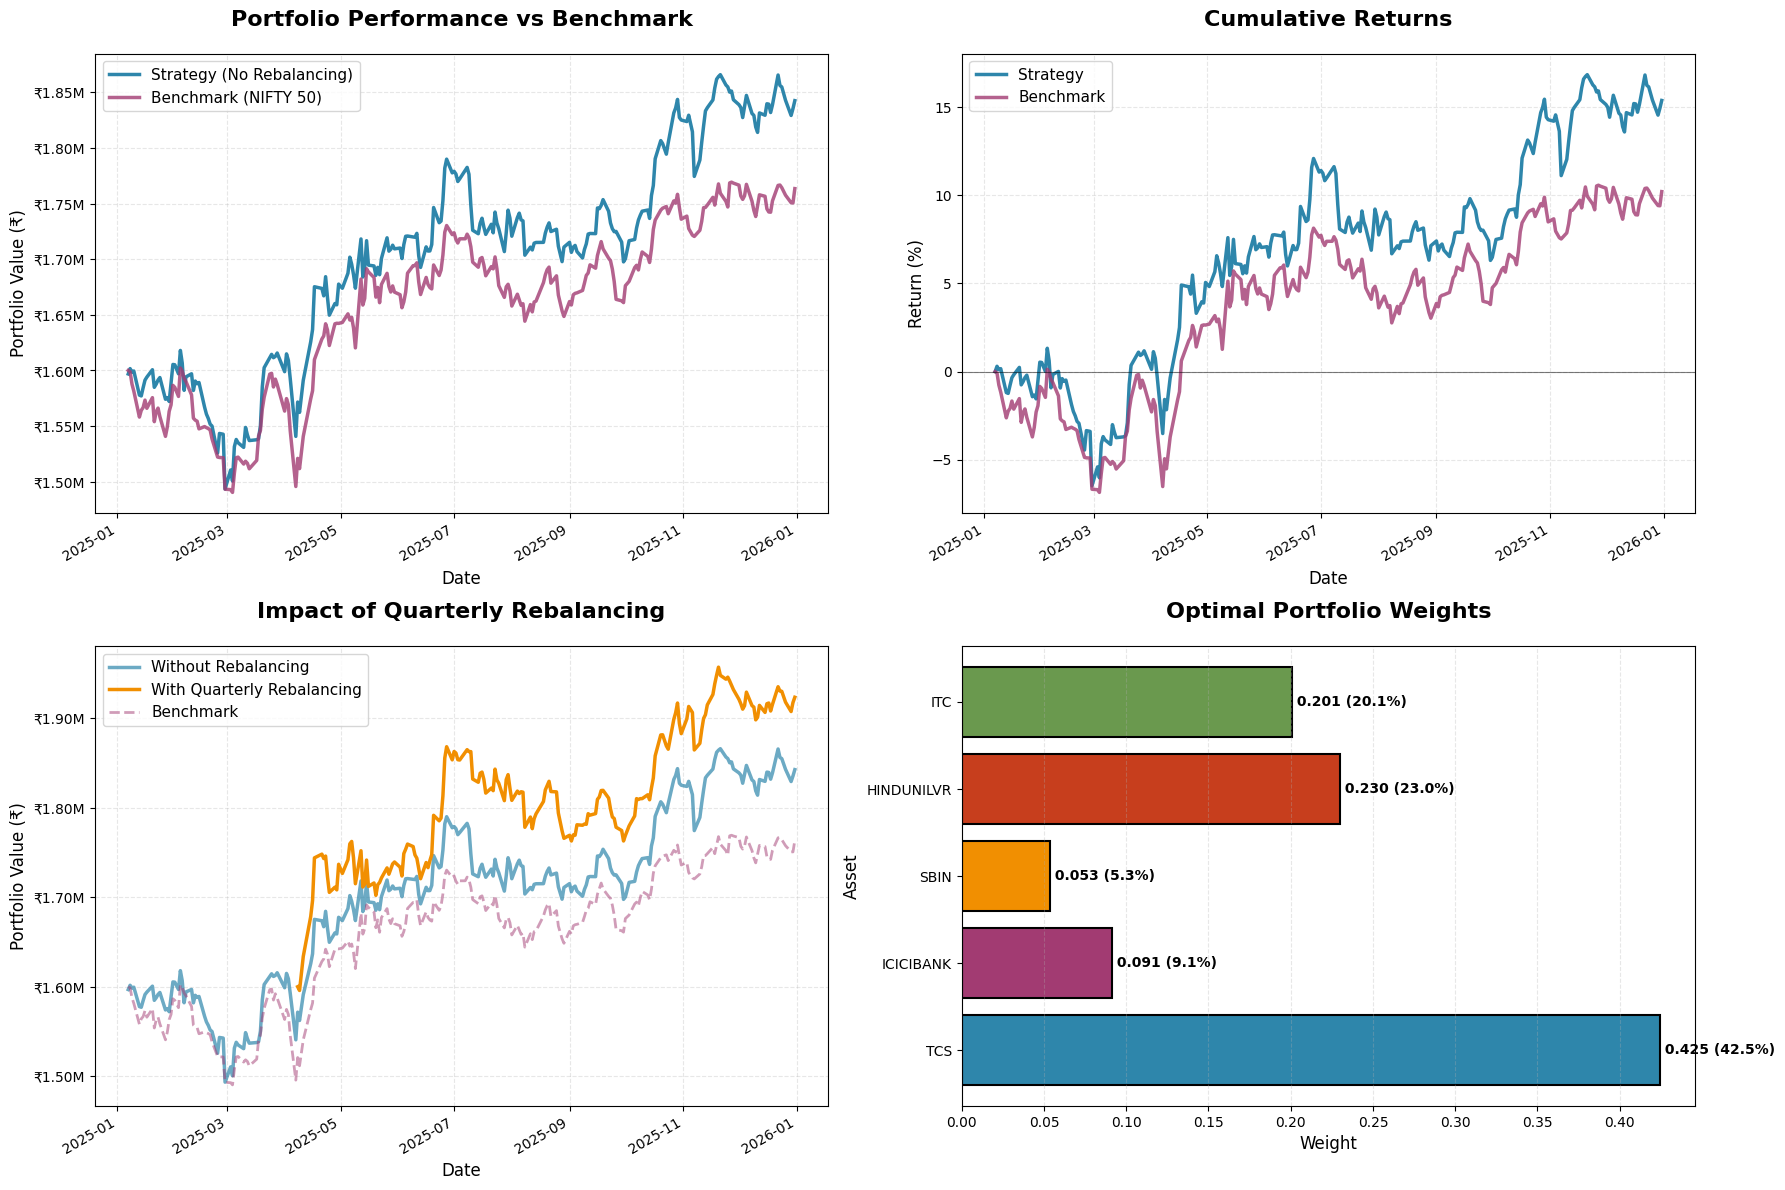

In [65]:
def main():
    """
    Main execution pipeline with train/test split to avoid look-ahead bias.
    
    PHASE 1: DATA PREPARATION
    ─────────────────────────
    • Download historical price data (train: ~2 yrs, test: ~1 yr)
    • Compute statistics with Ledoit-Wolf covariance shrinkage
    
    PHASE 2: PORTFOLIO OPTIMIZATION
    ────────────────────────────────
    • Auto-scale penalty coefficient λ for cardinality constraint
    • Build and normalize QUBO matrix
    • Solve with simulated annealing (with fallback cardinality enforcement)
    • Optimize portfolio weights using convex optimization
    
    PHASE 3: BACKTESTING & REBALANCING
    ───────────────────────────────────
    • Backtest static strategy (buy & hold) on test data
    • Implement quarterly rebalancing strategy
    • Compare performance vs NIFTY 50 benchmark
    
    PHASE 4: REPORTING & VISUALIZATION
    ───────────────────────────────────
    • Generate performance plots and metrics
    • Print detailed financial report
    """
    print("="*80)
    print(" END-TO-END PORTFOLIO OPTIMIZATION WITH SIMULATED ANNEALING")
    print("="*80)
    print(" Recreation of Quantum Portfolio Optimization with Classical SA")
    print("="*80 + "\n")
    
    # Make sure plots directory exists
    os.makedirs('plots', exist_ok=True)
    
    # ========================================================================
    # CONFIGURATION
    # ========================================================================
    
    TICKERS = [
        'TCS.NS',
        'INFY.NS',
        'HDFCBANK.NS',
        'ICICIBANK.NS',
        'SBIN.NS',
        'HINDUNILVR.NS',
        'ITC.NS',
        'LT.NS',
        'RELIANCE.NS',
        'BHARTIARTL.NS'
    ]
    
    BENCHMARK = '^NSEI'
    END_DATE = datetime(2026, 1, 1)
    START_DATE = datetime(2023, 1, 1)
    INITIAL_CAPITAL = 1600000
    
    # QUBO parameters
    Q_RISK_AVERSION = 0.5
    B_ASSETS = 5
    
    # ========================================================================
    # STEP 1: DATA COLLECTION
    # ========================================================================
    
    print(f"\n{'='*80}")
    print("STEP 1: DATA COLLECTION")
    print(f"{'='*80}\n")
    
    prices, benchmark_prices = download_data(TICKERS, BENCHMARK, START_DATE, END_DATE)
    print(f"Total data points: {len(prices)} days")
    
    # Train/Test split: First 2 years for training, last year for testing
    # This avoids look-ahead bias
    train_size = int(0.67 * len(prices))  # ~2 years
    train_prices = prices.iloc[:train_size]
    test_prices = prices.iloc[train_size:]
    test_benchmark = benchmark_prices.iloc[train_size:]
    
    print(f"Train: {train_prices.index[0].date()} → {train_prices.index[-1].date()} ({len(train_prices)} days)")
    print(f"Test:  {test_prices.index[0].date()} → {test_prices.index[-1].date()} ({len(test_prices)} days)")
    
    # Compute statistics ONLY on training data
    mu_train, cov_train, returns_train = compute_statistics(train_prices)
    
    # ========================================================================
    # STEP 2-5: INITIAL PORTFOLIO CONSTRUCTION (on training data)
    # ========================================================================
    
    print(f"\n{'='*80}")
    print("STEP 2-5: PORTFOLIO CONSTRUCTION (trained on {}-{})".format(
        train_prices.index[0].date(), train_prices.index[-1].date()))
    print(f"{'='*80}")
    
    # Auto-scale lambda
    LAMBDA_PENALTY = compute_lambda(mu_train, cov_train, Q_RISK_AVERSION, B_ASSETS, alpha=2.0)
    
    # Build QUBO
    Q = build_qubo(mu_train, cov_train, Q_RISK_AVERSION, LAMBDA_PENALTY, B_ASSETS)
    
    # Solve with SA
    selected, energy = solve_qubo_sa(Q, mu_train, num_reads=1000, B=B_ASSETS, seed=42)
    
    # Optimize weights
    weights = optimize_weights(mu_train, cov_train, selected)
    
    # Compute metrics (on training data)
    metrics = compute_metrics(weights, mu_train, cov_train, risk_free_rate=0.0)
    
    # ========================================================================
    # STEP 6: BACKTESTING on TEST DATA (13 months)
    # ========================================================================
    
    print(f"\n{'='*80}")
    print("STEP 6: BACKTESTING ON TEST DATA")
    print(f"{'='*80}\n")
    
    portfolio_values = backtest(test_prices, weights, INITIAL_CAPITAL)
    benchmark_values = backtest_benchmark(test_benchmark, INITIAL_CAPITAL)
    
    print(f"Backtest: {test_prices.index[0].date()} → {test_prices.index[-1].date()}")
    print(f"Initial:  ₹{portfolio_values.iloc[0]:,.0f}")
    print(f"Final:    ₹{portfolio_values.iloc[-1]:,.0f}")
    
    # ========================================================================
    # STEP 7: QUARTERLY REBALANCING on TEST DATA
    # ========================================================================
    
    print(f"\n{'='*80}")
    print("STEP 7: QUARTERLY REBALANCING ON TEST DATA")
    print(f"{'='*80}")
    
    portfolio_rebalanced, rebalance_info = rebalance_portfolio(
        test_prices, 
        TICKERS,
        INITIAL_CAPITAL,
        Q_RISK_AVERSION,
        LAMBDA_PENALTY,
        B_ASSETS,
        rebalance_months=3,
        lookback_days=252
    )
    
    # ========================================================================
    # STEP 8: REPORTING
    # ========================================================================
    
    print(f"\n{'='*80}")
    print("STEP 8: VISUALIZATION & REPORTING")
    print(f"{'='*80}")
    
    fig = plot_results(
        portfolio_values,
        benchmark_values,
        portfolio_rebalanced,
        TICKERS,
        weights
    )
    
    plt.savefig('plots/portfolio_results.png', dpi=300, bbox_inches='tight')
    print("\n✓ Plots saved: plots/portfolio_results.png")
    
    print_final_report(
        INITIAL_CAPITAL,
        portfolio_values.iloc[-1].item(),
        INITIAL_CAPITAL,
        benchmark_values.iloc[-1].item(),
        portfolio_rebalanced.iloc[-1].item(),
        portfolio_values,
        benchmark_values,
        portfolio_rebalanced,
        metrics,
        TICKERS,
        weights
    )
    
    print("="*80)
    print(" EXECUTION COMPLETED SUCCESSFULLY")
    print("="*80)


if __name__ == "__main__":
    main()